# Cancelamento de reservas de hotel: modelo

**Pergunta:** quais reservas têm mais chance de ser canceladas?

**Este notebook** escolhe o modelo de regressão logística com as 13 variáveis que saíram da triagem (`01_exploratoria`, `02_variaveis` e `03_variaveis_em_conjunto`) e o avalia em 2017. A escolha usa só o **treino** (chegadas de 2015 e 2016): a seleção stepwise pelo BIC, a conferência dos sinais em 2015 e em 2016 e os ajustes nas candidatas. O **teste** (2017) só entra na seção 8, com o modelo fechado.

**Momento do score:** o modelo é calculado alguns dias depois da reserva, junto com a ligação de confirmação. Por isso o pedido especial, que pode ser feito depois da reserva, pode entrar (notebook 01, Decisões para o grupo, item 8).

## Resumo

- **Modelo:** 9 variáveis, todas com o mesmo sinal em 2015 e em 2016: antecedência, pedido especial, segmento (agência online, grupos e demais), agência online com até 8 dias, paga por empresa, hotel, já veio, sozinho e 2 ou mais crianças.
- **Os fatores mais fortes:** reservas feitas com mais de 25 dias, sem pedido especial e pela agência online cancelam mais.
- **Em 2017:** AUC de 0,727. Ligando para 20% das reservas, o modelo encontra 38,6% dos cancelamentos, contra 33,1% da melhor regra simples; a partir de 40% das ligações, os dois empatam.
- **Ponto de corte:** ligar para as reservas com probabilidade acima de 30,2%. Em 2017, são 25,8% das reservas, que concentram 44,6% dos cancelamentos (a melhor regra simples encontra 41,3% com as mesmas ligações).
- **Limitação:** o modelo prevê 29,2% de cancelamento em 2017, contra 31,9% reais. Da alta de 5,5 pontos de 2017, só 1,3 vem do perfil das reservas; 4,2 são comportamento, que o modelo não capta.

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_auc_score

sys.path.append('..')   # o módulo de funções do projeto fica em analise/
from funcoes import (CORES, usar_tabelas_simples, aplicar_estilo, preparar_base, montar_variaveis,
                     SITUACAO_VARIAVEIS, NOMES_VARIAVEIS, ajustar_logistica, stepwise, stepwise_com_sinais,
                     comparar_modelos, coeficientes_por_periodo, razoes_de_chances, curva_ganho,
                     grafico_ganho, grupos_de_risco, calibracao, hosmer_lemeshow, taxa_por_bloco)

aplicar_estilo()
usar_tabelas_simples()   # todas as tabelas: nomes numa linha, índice como coluna, 4 casas
pd.set_option('display.max_rows', 100)


def nomes(historico):
    # troca o nome da coluna pelo nome de exibição na tabela do stepwise
    return historico.assign(variavel=historico['variavel'].map(NOMES_VARIAVEIS).fillna(''))

## 1. A base do modelo

#### Treino e candidatas

As variáveis no formato do 02 (`montar_variaveis`), sem o canal, que saiu por multicolinearidade no 03. Cada variável é categórica, e a referência é o nível maior.

In [2]:
# base, treino e as 13 candidatas
hotel = pd.read_csv('../../dados/hotel_bookings.csv')
base, _ = preparar_base(hotel)
dados = montar_variaveis(base)
treino = dados[dados['arrival_date_year'] < 2017]
candidatas = [v for v in SITUACAO_VARIAVEIS if v != 'canal']
print('Treino:', len(treino), f"| cancelamento {treino['is_canceled'].mean():.1%}")
print('Candidatas:', ', '.join(NOMES_VARIAVEIS[v] for v in candidatas))

Treino: 67455 | cancelamento 26.8%
Candidatas: antecedência, noites, diária, sozinho, 2 ou mais crianças, com bebê, pedido especial, já veio, hotel, segmento, tem agência, paga por empresa, temporada


**Leitura.**

- **Treino: 67.455 reservas, 26,8% de cancelamento,** e 13 candidatas.

## 2. Primeira seleção

O stepwise começa sem nenhuma variável e, a cada passo, põe a candidata que mais reduz o **BIC**; depois de cada entrada, confere se alguma variável que já estava deve sair. Para quando nenhuma entrada ou saída reduz o BIC. Cada variável entra ou sai inteira, com todas as suas dummies.

**Por que o BIC:** com 67 mil reservas, quase qualquer efeito tem p-valor abaixo de 0,05, e a multa do AIC (2 pontos por coeficiente) é pequena; os dois deixam entrar efeitos pequenos demais para importar. O BIC multa cada coeficiente com ln(n), cerca de 11 pontos aqui, e fica com o modelo mais simples, que é o que vai para a apresentação. É também o critério das escolhas do 02 e do 03.

#### Passos

In [3]:
# stepwise pelo BIC com as 13 candidatas (treino)
primeira, historico = stepwise(treino, candidatas, criterio='bic')
nomes(historico).round(1)

passo,acao,variavel,bic,queda
0,início,,78384.7000,
1,entra,antecedência,75086.6000,3298.1000
2,entra,pedido especial,73020.3000,2066.3000
3,entra,segmento,69814.8000,3205.5000
4,entra,temporada,69653.5000,161.3000
5,entra,hotel,69518.8000,134.7000
6,entra,paga por empresa,69411.2000,107.6000
7,entra,2 ou mais crianças,69363.1000,48.1000
8,entra,noites,69321.8000,41.3000
9,entra,sozinho,69287.4000,34.4000


**Leitura.**

- **Entram 11 das 13 candidatas; ficam de fora a diária e "com bebê".** "Com bebê" fica de fora com o pedido especial no modelo, como o 02 antecipava (seção 3.6: 84,7% das reservas com bebê fizeram pedido).
- **Três variáveis fazem quase todo o trabalho:** antecedência, pedido especial e segmento reduzem o BIC em 3.298, 2.066 e 3.206 pontos. As seguintes reduzem de 161 para baixo.
- **Tem agência é a última a entrar, com queda de 7,0 pontos.**

## 3. Os sinais em 2015 e em 2016

#### Coeficientes em cada ano

O modelo da primeira seleção ajustado no treino todo, só em 2015 e só em 2016. Coeficiente negativo quer dizer menos chance de cancelar que a referência, com as outras variáveis iguais. A regra da análise: o sinal precisa ser o mesmo nos dois anos.

In [4]:
# coeficientes da primeira seleção: treino todo, 2015 e 2016
coeficientes_por_periodo(treino, 'is_canceled ~ ' + ' + '.join(primeira), primeira).round(4)

coeficiente,coef,p_valor,coef_2015,coef_2016,mesmo_sinal
antecedencia[T.0],-1.8688,0,-1.8173,-1.8876,sim
antecedencia[T.1–8],-1.1487,0,-1.1547,-1.1653,sim
antecedencia[T.9–25],-0.3535,0,-0.6432,-0.2541,sim
pedido_especial[T.fez pedido],-1.1587,0,-0.4493,-1.3973,sim
segmento[T.demais],-1.0920,0,-0.6700,-1.2555,sim
temporada[T.baixa],-0.0700,0.0083,0.0512,-0.1226,não
temporada[T.alta],0.2343,0,0.6730,0.0586,sim
hotel[T.resort],-0.2739,0,-0.3891,-0.3070,sim
paga_empresa[T.paga por empresa],-0.5999,0,-0.4579,-0.5737,sim
duas_criancas[T.sim],0.3585,0,0.1858,0.3608,sim


**Leitura.**

- **14 dos 15 coeficientes mantêm o sinal nos dois anos.**
- **A temporada baixa inverte:** +0,05 em 2015 e −0,12 em 2016. Em 2015, a baixa é só novembro (02, seção 2.2).
- **Tem agência mantém o sinal, mas vai contra a comparação direta:** no modelo, a reserva sem agência cancela mais (+0,18); sozinha, cancela 14,5%, contra 28,8% (02, seção 3.17). A seção 4 examina.

## 4. Ajustes nas candidatas

Três ajustes, cada um decidido pelas mesmas regras: o BIC e o sinal em 2015 e em 2016.

#### Temporada em 2 níveis

A temporada com dois níveis, alta (julho e agosto) × resto do ano, junta a baixa à média. A tabela compara o modelo da primeira seleção com essa troca.

In [5]:
# temporada em 3 × 2 níveis, no modelo da primeira seleção (treino)
com_temporada_alta = [('temporada_alta' if v == 'temporada' else v) for v in primeira]
comparar_modelos(treino, {
    'primeira seleção': 'is_canceled ~ ' + ' + '.join(primeira),
    'temporada em 2 níveis': 'is_canceled ~ ' + ' + '.join(com_temporada_alta),
}, base_comparacao='primeira seleção')

modelo,n_coeficientes,AIC,dif_AIC,BIC,dif_BIC,AIC_vs_base,BIC_vs_base
temporada em 2 níveis,14,69123.1000,5,69259.9000,0,5,-4.1000
primeira seleção,15,69118.1000,0,69264,4.1000,0,0


**Leitura.**

- **A temporada em 2 níveis melhora o BIC em 4,1 pontos,** com um coeficiente a menos, e elimina a temporada baixa, que invertia. **Fica em 2 níveis.**

#### Segmento em 3 níveis e agência online × antecedência

No 02, o segmento ficou em 2 grupos porque, olhando só o segmento, grupos e agência online trocam de lugar entre 2015 e 2016 (seção 3.11). Com as outras variáveis no modelo, a pergunta volta. A interação testa se o efeito da antecedência é diferente na agência online, de duas formas: com as três faixas curtas de antecedência e só com "até 8 dias".

In [6]:
# segmento em 3 níveis e interação com a antecedência (treino)
treino = treino.assign(**{
    f'online_{nome}': pd.Categorical(np.where((treino['segmento3'] == 'agência online') & (treino['antecedencia'] == faixa),
                                              'sim', 'não'), ['não', 'sim'])
    for nome, faixa in [('0', '0'), ('1_8', '1–8'), ('9_25', '9–25')]})
com_segmento3 = [('segmento3' if v == 'segmento' else v) for v in com_temporada_alta]
formula_seg3 = 'is_canceled ~ ' + ' + '.join(com_segmento3)
comparar_modelos(treino, {
    'temporada em 2 níveis': 'is_canceled ~ ' + ' + '.join(com_temporada_alta),
    'segmento em 3 níveis': formula_seg3,
    'segmento em 3 níveis + online × 3 faixas curtas': formula_seg3 + ' + online_0 + online_1_8 + online_9_25',
    'segmento em 3 níveis + online até 8 dias': formula_seg3 + ' + online_ate8',
}, base_comparacao='temporada em 2 níveis')

modelo,n_coeficientes,AIC,dif_AIC,BIC,dif_BIC,AIC_vs_base,BIC_vs_base
segmento em 3 níveis + online até 8 dias,16,67804.2000,0.4000,67959.3000,0,-1318.9000,-1300.6000
segmento em 3 níveis + online × 3 faixas curtas,18,67803.8000,0,67977.1000,17.8000,-1319.3000,-1282.8000
segmento em 3 níveis,15,68153.5000,349.7000,68299.4000,340.2000,-969.6000,-960.5000
temporada em 2 níveis,14,69123.1000,1319.3000,69259.9000,1300.6000,0,0


**Leitura.**

- **O segmento em 3 níveis melhora o BIC em 960,5 pontos:** separar a agência online dos grupos acrescenta muito, com as outras variáveis no modelo.
- **A interação "agência online até 8 dias" melhora mais 340,2 pontos** (1.300,6 no total).
- **A interação com as três faixas curtas fica 17,8 pontos de BIC atrás,** com dois coeficientes a mais. O AIC quase não separa as duas (0,4 ponto); vale o BIC, porque a diferença passa de 2 pontos.
- **Ficam o segmento em 3 níveis e a interação "agência online até 8 dias".**

#### Sinais do segmento e da interação

Os coeficientes do segmento em 3 níveis e das duas formas da interação, em cada ano.

In [7]:
# sinais do segmento em 3 níveis e da interação em cada ano (treino)
pd.concat([
    coeficientes_por_periodo(treino, formula_seg3 + ' + online_0 + online_1_8 + online_9_25',
                             ['segmento3', 'online_0', 'online_1_8', 'online_9_25']),
    coeficientes_por_periodo(treino, formula_seg3 + ' + online_ate8', ['online_ate8']),
]).round(4)

coeficiente,coef,p_valor,coef_2015,coef_2016,mesmo_sinal
segmento3[T.grupos],-1.0518,0,-0.3023,-1.4847,sim
segmento3[T.demais],-1.5481,0,-0.9172,-1.7444,sim
online_0[T.sim],-1.4520,0,-1.7757,-1.2893,sim
online_1_8[T.sim],-1.1340,0,-1.1601,-1.1449,sim
online_9_25[T.sim],0.0003,0.9955,0.0733,-0.1146,não
online_ate8[T.sim],-1.1909,0,-1.2913,-1.1499,sim


**Leitura.**

- **O segmento em 3 níveis mantém o sinal nos dois anos:** grupos, −0,30 em 2015 e −1,48 em 2016; demais, −0,92 e −1,74, sempre em relação à agência online. A troca de lugar do 02 aparecia com o segmento sozinho e some com as outras variáveis no modelo.
- **Na agência online, a reserva de 0 dias e a de 1 a 8 dias mantêm o sinal** (−1,78 e −1,29; −1,16 e −1,14). **A de 9 a 25 dias inverte e não tem efeito** (+0,07 e −0,11; p-valor de 0,996): por isso a interação fica só com "até 8 dias" (−1,29 e −1,15).
- **Em português:** na agência online, a reserva de última hora cancela bem menos; o risco da agência online está nas reservas feitas com antecedência.

#### Tem agência

No modelo, a reserva sem agência cancela mais que a com agência. As duas tabelas comparam as duas diretamente, dentro de cada segmento e dentro de cada faixa de antecedência, em cada ano.

In [8]:
# taxa com e sem agência dentro de cada segmento, por ano (treino)
def taxa_por(coluna):
    return (treino.groupby([coluna, 'tem_agencia', 'arrival_date_year'], observed=True)['is_canceled']
            .agg(reservas='size', taxa='mean').unstack()
            .pipe(lambda t: t.set_axis([f'{a}_{b}' for a, b in t.columns], axis=1)).round(4))

taxa_por('segmento3')

segmento3,tem_agencia,reservas_2015,reservas_2016,taxa_2015,taxa_2016
agência online,com agência,6004,27270,0.2705,0.3586
agência online,sem agência,63,159,0.0317,0.0881
grupos,com agência,3332,2549,0.4025,0.2554
grupos,sem agência,268,1252,0.0746,0.2652
demais,com agência,6079,12669,0.1895,0.1677
demais,sem agência,2399,5411,0.1413,0.1251


**Leitura.**

- **Sem agência cancela menos em 5 das 6 combinações de segmento e ano:** na agência online, 3,2% contra 27,1% em 2015 e 8,8% contra 35,9% em 2016; nos demais, 14,1% contra 19,0% e 12,5% contra 16,8%.
- **A exceção são os grupos em 2016:** 26,5% sem agência, contra 25,5% com.

In [9]:
# taxa com e sem agência dentro de cada faixa de antecedência, por ano (treino)
taxa_por('antecedencia')

antecedencia,tem_agencia,reservas_2015,reservas_2016,taxa_2015,taxa_2016
mais de 25,com agência,10457,30430,0.3285,0.3368
mais de 25,sem agência,722,2283,0.1690,0.2431
0,com agência,619,1267,0.0937,0.0781
0,sem agência,784,1590,0.0472,0.0572
1–8,com agência,1980,5158,0.0955,0.1208
1–8,sem agência,769,2043,0.1573,0.1028
9–25,com agência,2359,5633,0.1844,0.2812
9–25,sem agência,455,906,0.1780,0.1843


**Leitura.**

- **Sem agência cancela menos em 7 das 8 combinações de antecedência e ano:** acima de 25 dias, por exemplo, 16,9% contra 32,9% em 2015 e 24,3% contra 33,7% em 2016. A exceção é 1 a 8 dias em 2015 (15,7% contra 9,6%).
- **O sinal positivo do modelo não aparece em nenhuma comparação direta:** é o que sobra depois de descontar as outras variáveis ao mesmo tempo (o 03 mostrou o mesmo com o canal). Melhora o ajuste em 7,0 pontos de BIC, mas não se explica para a diretoria nem para o analista de BI.
- **Tem agência sai.**

## 5. Seleção final

As candidatas com os ajustes da seção 4: a temporada em 2 níveis, o segmento em 3 níveis e a interação "agência online até 8 dias"; tem agência fica de fora. O stepwise roda com a conferência dos sinais: se um coeficiente inverte entre 2015 e 2016, a variável dele sai e o stepwise roda de novo, até nenhum sinal inverter (`stepwise_com_sinais`).

#### Variáveis que saem por inverter o sinal

In [10]:
# stepwise com a conferência dos sinais (treino)
candidatas_finais = (['segmento3', 'temporada_alta', 'online_ate8']
                     + [v for v in candidatas if v not in ('segmento', 'temporada', 'tem_agencia')])
finais, historico_final, rodadas = stepwise_com_sinais(treino, candidatas_finais)
rodadas.assign(variavel=rodadas['variavel'].map(NOMES_VARIAVEIS)).round(4)

rodada,variavel,coeficiente,coef_2015,coef_2016
1,temporada (alta × resto),temporada_alta[T.alta],0.6785,-0.0400
2,diária,diaria[T.até 59],0.2650,-0.2712


**Leitura.**

- **Duas variáveis saem por inverter o sinal.** Na primeira rodada, a temporada alta: +0,68 em 2015 e −0,04 em 2016. Com o segmento em 3 níveis e a interação, julho e agosto deixam de acrescentar em 2016. Na segunda rodada, a diária: +0,27 e −0,27, como já acontecia com a diária sozinha (02, seção 3.3).

#### Passos da última rodada

In [11]:
nomes(historico_final).round(1)

passo,acao,variavel,bic,queda
0,início,,78384.7000,
1,entra,antecedência,75086.6000,3298.1000
2,entra,pedido especial,73020.3000,2066.3000
3,entra,segmento (3 níveis),68687.4000,4333
4,entra,agência online até 8 dias,68349.6000,337.8000
5,entra,paga por empresa,68248.9000,100.7000
6,entra,hotel,68178.3000,70.5000
7,entra,já veio,68137.5000,40.9000
8,entra,sozinho,68104.6000,32.9000
9,entra,2 ou mais crianças,68094.2000,10.4000


**Leitura.**

- **O modelo final tem 9 variáveis.** Além da temporada e da diária, ficam de fora as noites e "com bebê", que não reduzem o BIC.
- **O segmento em 3 níveis é a variável que mais reduz o BIC (4.333 pontos),** seguido da antecedência e do pedido especial. A interação vem em quarto (337,8).
- **O BIC final é 68.094,2,** contra 69.264,0 da primeira seleção: 1.169,8 pontos melhor, com 3 coeficientes a menos.

## 6. O modelo escolhido

#### Razões de chances

Cada coeficiente como razão de chances ($e^b$), com o intervalo de 95%. Razão de chances abaixo de 1 quer dizer menos chance de cancelar que a referência, com as outras variáveis iguais; acima de 1, mais. A referência de cada variável está entre parênteses.

In [12]:
# o modelo escolhido, ajustado no treino
formula_final = 'is_canceled ~ ' + ' + '.join(finais)
modelo = ajustar_logistica(formula_final, treino)
referencias = {v: treino[v].cat.categories[0] for v in finais}
tabela = razoes_de_chances(modelo)
tabela.index = [f"{NOMES_VARIAVEIS[v]}: {t.split('[T.')[1].rstrip(']')} (ref.: {referencias[v]})"
                for t in tabela.index for v in finais if t.startswith(f'{v}[')]
tabela.rename_axis('nivel').round(4)

nivel,coef,razao_chances,ic_inf,ic_sup,p_valor
antecedência: 0 (ref.: mais de 25),-1.3273,0.2652,0.2320,0.3031,0
antecedência: 1–8 (ref.: mais de 25),-0.5394,0.5831,0.5324,0.6385,0
antecedência: 9–25 (ref.: mais de 25),-0.4368,0.6461,0.6115,0.6827,0
pedido especial: fez pedido (ref.: nenhum),-1.4222,0.2412,0.2307,0.2521,0
segmento (3 níveis): grupos (ref.: agência online),-1.0250,0.3588,0.3372,0.3818,0
segmento (3 níveis): demais (ref.: agência online),-1.5239,0.2179,0.2072,0.2291,0
agência online até 8 dias: sim (ref.: não),-1.2806,0.2779,0.2458,0.3141,0
paga por empresa: paga por empresa (ref.: sem empresa),-0.3725,0.6890,0.6177,0.7686,0
hotel: resort (ref.: urbano),-0.1916,0.8257,0.7937,0.8590,0
já veio: já veio (ref.: nunca veio),-0.6082,0.5444,0.4497,0.6590,0


**Leitura.**

- **Os três fatores mais fortes:**
  - **antecedência:** a reserva feita no mesmo dia tem 0,27 vez a chance de cancelar da feita com mais de 25 dias; de 1 a 8 dias, 0,58; de 9 a 25 dias, 0,65;
  - **pedido especial:** quem faz um pedido tem 0,24 vez a chance de quem não faz;
  - **segmento:** em relação à agência online, grupos têm 0,36 vez a chance, e os demais segmentos, 0,22. Na agência online, a reserva com até 8 dias tem ainda 0,28 vez a chance (a interação).
- **Os outros:** já veio (0,54), paga por empresa (0,69), resort (0,83) e sozinho (0,84) cancelam menos; 2 ou mais crianças cancelam mais (1,27).
- **Nenhum intervalo de 95% cruza o 1.**

#### Sinais em 2015 e em 2016

In [13]:
coeficientes_por_periodo(treino, formula_final, finais).round(4)

coeficiente,coef,p_valor,coef_2015,coef_2016,mesmo_sinal
antecedencia[T.0],-1.3273,0,-1.2427,-1.3711,sim
antecedencia[T.1–8],-0.5394,0,-0.6231,-0.5410,sim
antecedencia[T.9–25],-0.4368,0,-0.7174,-0.3587,sim
pedido_especial[T.fez pedido],-1.4222,0,-0.5309,-1.6316,sim
segmento3[T.grupos],-1.0250,0,-0.2602,-1.3635,sim
segmento3[T.demais],-1.5239,0,-0.9325,-1.6829,sim
online_ate8[T.sim],-1.2806,0,-1.3162,-1.2642,sim
paga_empresa[T.paga por empresa],-0.3725,0,-0.3916,-0.2751,sim
hotel[T.resort],-0.1916,0,-0.3287,-0.1276,sim
ja_veio[T.já veio],-0.6082,0,-0.3720,-0.6886,sim


**Leitura.**

- **Os 12 coeficientes mantêm o sinal em 2015 e em 2016.**
- **O tamanho muda entre os anos em alguns:** o pedido especial (−0,53 em 2015 e −1,63 em 2016) e os grupos (−0,26 e −1,36). 2015 só tem julho a dezembro e mais blocos de quartos (04, seção 2).

#### Com e sem o pedido especial

O pedido especial entra porque o score é calculado alguns dias depois da reserva. A tabela mostra o que ele acrescenta: o modelo escolhido com e sem ele.

In [14]:
# o modelo escolhido com e sem o pedido especial (treino)
comparar_modelos(treino, {
    'modelo escolhido': formula_final,
    'sem o pedido especial': 'is_canceled ~ ' + ' + '.join(v for v in finais if v != 'pedido_especial'),
}, base_comparacao='modelo escolhido')

modelo,n_coeficientes,AIC,dif_AIC,BIC,dif_BIC,AIC_vs_base,BIC_vs_base
modelo escolhido,12,67975.6000,0,68094.2000,0,0,0
sem o pedido especial,11,72352.5000,4376.8000,72461.9000,4367.7000,4376.8000,4367.7000


**Leitura.**

- **Sem o pedido especial, o BIC piora 4.367,7 pontos.** Com as outras variáveis no modelo, é a variável que mais acrescenta depois do segmento. Por isso o momento do score (alguns dias depois da reserva) importa para o modelo.

## 7. A régua: uma regra simples

O modelo só vale a pena se encontrar mais cancelamentos que uma regra que o hotel aplicaria sem modelo, ligando para o mesmo número de reservas. A régua é a regra **"agência online com mais de 30 dias de antecedência"** (notebook 02 do grupo), em duas versões: com as reservas marcadas contatadas ao acaso, e ordenadas da maior para a menor antecedência. As probabilidades do modelo têm muitos empates; quando o corte cai num grupo empatado, entra a parte proporcional dele (`parcela_capturada`).

#### Cancelamentos encontrados no treino

In [15]:
# pontuação de cada reserva: modelo, regra ao acaso e regra ordenada pela antecedência
def pontuacoes(d):
    online_30 = (base.loc[d.index, 'market_segment'] == 'Online TA') & (base.loc[d.index, 'lead_time'] > 30)
    return {'modelo': modelo.predict(d).round(10),
            'regra ao acaso': online_30.astype(int),
            'regra ordenada': np.where(online_30, base.loc[d.index, 'lead_time'], -1)}, online_30.mean()

fracoes = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50]
p_treino, marca_treino = pontuacoes(treino)
print(f'A regra marca {marca_treino:.1%} das reservas do treino.')
curva_ganho(treino['is_canceled'], p_treino, fracoes + [marca_treino]).round(4)

A regra marca 31.1% das reservas do treino.


pct_contatadas,modelo,regra ao acaso,regra ordenada
0.0500,0.1264,0.0779,0.0932
0.1000,0.2471,0.1557,0.1753
0.2000,0.4345,0.3114,0.3282
0.3000,0.5359,0.4672,0.4686
0.4000,0.6313,0.5508,0.5508
0.5000,0.7416,0.6256,0.6256
0.3108,0.5458,0.4840,0.4840


**Leitura.**

- **No treino, o modelo encontra mais cancelamentos que a regra em todos os pontos:** ligando para 10% das reservas, 24,7% contra 17,5% da regra ordenada; para 20%, 43,5% contra 32,8%; para os 31,1% que a regra marca, 54,6% contra 48,4%.

## 8. Avaliação em 2017

O teste entra aqui pela primeira vez, com o modelo fechado.

#### Ordenação: AUC

A AUC é a chance de o modelo dar probabilidade maior a uma reserva cancelada que a uma que veio, sorteando uma de cada: 0,5 é o acaso, 1 é a ordenação perfeita.

In [16]:
# AUC no treino e no teste
teste = dados[dados['arrival_date_year'] == 2017]
prob_teste = modelo.predict(teste)
pd.Series({'treino': roc_auc_score(treino['is_canceled'], modelo.predict(treino)),
           'teste (2017)': roc_auc_score(teste['is_canceled'], prob_teste)}, name='AUC').rename_axis('base').to_frame().round(4)

base,AUC
treino,0.7377
teste (2017),0.7266


**Leitura.**

- **AUC de 0,738 no treino e 0,727 em 2017.** A ordenação quase não perde força no ano novo.

#### Cancelamentos encontrados em 2017

O modelo contra a régua, ligando para a mesma parcela das reservas de 2017.

In [17]:
# curva de ganho no teste: modelo × regra
p_teste, marca_teste = pontuacoes(teste)
print(f'A regra marca {marca_teste:.1%} das reservas de 2017.')
ganho_teste = curva_ganho(teste['is_canceled'], p_teste, fracoes + [marca_teste])
ganho_teste.round(4)

A regra marca 44.3% das reservas de 2017.


pct_contatadas,modelo,regra ao acaso,regra ordenada
0.0500,0.1012,0.0747,0.0994
0.1000,0.1991,0.1494,0.1804
0.2000,0.3861,0.2987,0.3309
0.3000,0.4933,0.4481,0.4699
0.4000,0.6057,0.5975,0.6041
0.5000,0.6988,0.6962,0.6962
0.4428,0.6555,0.6615,0.6615


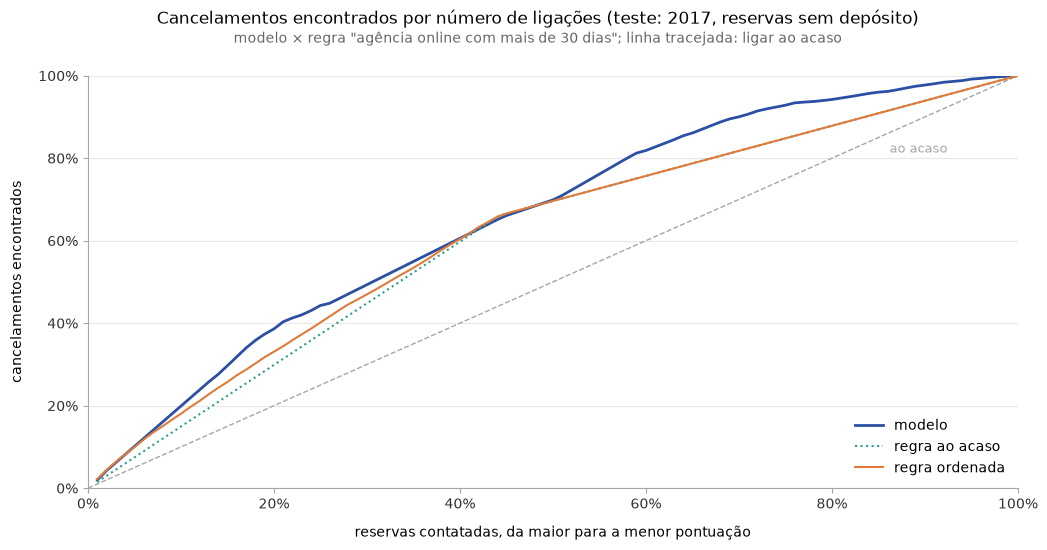

In [18]:
# o mesmo, em gráfico
curva = curva_ganho(teste['is_canceled'], p_teste, np.linspace(0.01, 1, 100))
grafico_ganho(curva, titulo='Cancelamentos encontrados por número de ligações (teste: 2017, reservas sem depósito)',
              subtitulo='modelo × regra "agência online com mais de 30 dias"; linha tracejada: ligar ao acaso',
              estilos={'modelo': {'color': CORES['principal'], 'linewidth': 2},
                       'regra ordenada': {'color': CORES['secundaria']},
                       'regra ao acaso': {'color': CORES['terciaria'], 'linestyle': ':'}})
plt.show()

**Leitura.**

- **Em 2017, o modelo encontra mais cancelamentos que a regra quando o hotel liga para 10% a 30% das reservas:** 19,9% contra 18,0% da regra ordenada com 10% das ligações; 38,6% contra 33,1% com 20%; 49,3% contra 47,0% com 30%.
- **A partir de 40%, os dois empatam:** 60,6% contra 60,4% com 40%, e 65,6% contra 66,2% nos 44,3% que a regra marca.
- **Por que a régua ficou mais forte em 2017:** a agência online cresceu (04, seção 4), e a regra é feita justamente sobre ela. Ela passa a marcar 44,3% das reservas, contra 31,1% no treino.
- **Para a recomendação:** o hotel não liga para quase metade das reservas. Na faixa de 10% a 30% das ligações, que é a que cabe numa equipe, o modelo encontra mais cancelamentos com o mesmo esforço.

#### Calibração: total e por grupo de risco

A probabilidade média prevista contra a taxa real, no total e em dez grupos de risco (pelos quantis da probabilidade; reservas empatadas ficam no mesmo grupo).

In [19]:
# calibração no teste: total e por grupo de risco
print(f"Prevista: {prob_teste.mean():.1%} | real: {teste['is_canceled'].mean():.1%}")
print('Hosmer-Lemeshow:', {k: round(v, 4) for k, v in hosmer_lemeshow(teste['is_canceled'], prob_teste).items()})
calibracao(teste['is_canceled'], prob_teste, grupos_de_risco(prob_teste)).rename_axis('grupo_de_risco').round(4)

Prevista: 29.2% | real: 31.9%
Hosmer-Lemeshow: {'estatistica': 499.2502, 'gl': 7, 'p_valor': 0.0}


grupo_de_risco,reservas,prob_media,taxa_real,dif_pp
1,3782,0.0442,0.0735,2.9310
2,3548,0.0813,0.1133,3.2031
3,3595,0.1561,0.1324,-2.3655
4,3675,0.2261,0.2615,3.5425
5,3750,0.2626,0.3821,11.9564
6,8623,0.2972,0.3325,3.5263
7,2127,0.3448,0.3310,-1.3824
8,6724,0.6148,0.6090,-0.5784
9,532,0.6752,0.6955,2.0292


**Leitura.**

- **O modelo prevê 29,2% de cancelamento em 2017; a taxa real é 31,9%.** A diferença de 2,7 pontos é a alta de 2017 que as variáveis não explicam (01, seção 5.2).
- **Os grupos de maior risco estão bem calibrados:** 61,5% previstos contra 60,9% reais no grupo 8, e 67,5% contra 69,6% no grupo 9. O maior erro é no grupo 5: 26,3% previstos contra 38,2% reais.
- **Os grupos têm tamanhos diferentes** porque milhares de reservas têm o mesmo perfil e a mesma probabilidade (o grupo 6 tem 8.623).
- **O Hosmer-Lemeshow rejeita a calibração** (p-valor abaixo de 0,0001), o que é esperado com 36 mil reservas e uma alta geral de 2,7 pontos. Para ordenar quem ligar, a calibração importa pouco; para estimar quantos cancelamentos esperar (overbooking), as probabilidades precisam de ajuste ao ano.

#### Calibração por segmento e por pedido especial

Os dois pontos que o `04_qualidade_teste` apontou: o perfil de 2017 tem mais agência online e mais pedidos especiais.

In [20]:
# calibração no teste por segmento e por pedido especial
pd.concat({'segmento': calibracao(teste['is_canceled'], prob_teste, teste['segmento3']),
           'pedido especial': calibracao(teste['is_canceled'], prob_teste, teste['pedido_especial'])},
          names=['variavel', 'nivel']).round(4)

variavel,nivel,reservas,prob_media,taxa_real,dif_pp
segmento,agência online,22558,0.3653,0.4092,4.3918
segmento,demais,10743,0.1463,0.1609,1.4601
segmento,grupos,3055,0.2648,0.2049,-5.9896
pedido especial,fez pedido,19239,0.2042,0.2644,6.0123
pedido especial,nenhum,17117,0.3910,0.3797,-1.1224


**Leitura.**

- **A alta de 2017 se concentra em dois grupos:** a agência online (36,5% previstos, 40,9% reais: +4,4 pontos) e quem fez pedido especial (20,4% contra 26,4%: +6,0 pontos).
- **Os grupos cancelam menos que o previsto** (26,5% contra 20,5%: −6,0 pontos).
- **O pedido especial continua separando bem** (26,4% contra 38,0% sem pedido), mas a diferença encolhe em 2017. É a variável cuja parcela mais cresceu no ano (04, seção 4).

## 9. A alta de 2017

O cancelamento sobe em 2017. A alta tem duas partes: **composição** (entram mais reservas com perfil de risco, que o modelo capta pelas variáveis) e **comportamento** (o mesmo perfil cancela mais, o que o modelo não capta). A probabilidade média prevista em cada período mede a composição; o resto da alta é comportamento. A comparação usa janeiro a agosto nos dois anos.

#### Composição e comportamento

In [21]:
# taxa real e prevista: janeiro a agosto de 2016 × 2017
jan_a_ago = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August']
mesmos_meses_2016 = treino[(treino['arrival_date_year'] == 2016) & base.loc[treino.index, 'arrival_date_month'].isin(jan_a_ago)]
periodos = pd.DataFrame({
    'taxa_real': [mesmos_meses_2016['is_canceled'].mean(), teste['is_canceled'].mean()],
    'prob_media_prevista': [modelo.predict(mesmos_meses_2016).mean(), prob_teste.mean()],
}, index=pd.Index(['2016 (jan–ago)', '2017 (jan–ago)'], name='periodo'))
alta = periodos['taxa_real'].diff().iloc[-1] * 100
composicao = periodos['prob_media_prevista'].diff().iloc[-1] * 100
print(f'Alta: {alta:.1f} pontos | composição: {composicao:.1f} | comportamento: {alta - composicao:.1f}')
periodos.round(4)

Alta: 5.5 pontos | composição: 1.3 | comportamento: 4.2


periodo,taxa_real,prob_media_prevista
2016 (jan–ago),0.2636,0.2796
2017 (jan–ago),0.3187,0.2922


**Leitura.**

- **De janeiro a agosto, o cancelamento sobe 5,5 pontos:** de 26,4% em 2016 para 31,9% em 2017.
- **1,3 ponto é composição:** a probabilidade média prevista sobe de 28,0% para 29,2%, porque 2017 tem mais reservas com perfil de risco, como mais agência online e mais antecedência longa (04, seção 4).
- **4,2 pontos são comportamento:** o mesmo perfil cancela mais em 2017. É a maior parte da alta, e o modelo não a capta.
- **Para a apresentação:** "a maior parte da alta de 2017 não vem do perfil das reservas: reservas parecidas passaram a cancelar mais". Entra como limitação, com a calibração (seção 8).

## 10. Ponto de corte

Até onde vale ligar? Com as reservas ordenadas da maior para a menor probabilidade, cada bloco de ligações a mais encontra uma taxa de cancelamento menor. O corte proposto é o **primeiro bloco de 5% em que a taxa fica abaixo da média do treino**: dali em diante, ligar encontra o mesmo que ligar ao acaso. Uma probabilidade não divide reservas empatadas: se o ponto cai num grupo de reservas com a mesma probabilidade, o corte fica antes dele. O corte sai do treino; 2017 só confere. O critério não usa custo: diz até onde ligar é mais eficiente que ligar ao acaso, não até onde dá lucro.

#### Taxa de cancelamento por bloco de ligações (treino)

In [22]:
# taxa de cancelamento a cada 5% de ligações, da maior para a menor probabilidade (treino)
prob_treino = modelo.predict(treino)
media_treino = treino['is_canceled'].mean()
blocos = taxa_por_bloco(treino['is_canceled'], prob_treino.round(10))
fim_corte = blocos.index[blocos['taxa_bloco'] < media_treino][0][0]
limiar = prob_treino.quantile(1 - fim_corte)
print(f'Média do treino: {media_treino:.1%} | primeiro bloco abaixo dela começa em {fim_corte:.0%} das reservas')
empatadas = (prob_treino.round(10) == round(limiar, 10)).sum()
print(f'Probabilidade nesse ponto: {limiar:.1%}, com {empatadas} reservas empatadas nesse valor')
print(f'Corte: ligar para as reservas com probabilidade acima de {limiar:.1%}')
blocos.round(4)

Média do treino: 26.8% | primeiro bloco abaixo dela começa em 25% das reservas


Probabilidade nesse ponto: 30.2%, com 8312 reservas empatadas nesse valor
Corte: ligar para as reservas com probabilidade acima de 30.2%


de,ate,taxa_bloco,cancel_acum
0,0.0500,0.6764,0.1264
0.0500,0.1000,0.6464,0.2471
0.1000,0.1500,0.5702,0.3536
0.1500,0.2000,0.4333,0.4345
0.2000,0.2500,0.2989,0.4904
0.2500,0.3000,0.2439,0.5359
0.3000,0.3500,0.2439,0.5815
0.3500,0.4000,0.2665,0.6313
0.4000,0.4500,0.2569,0.6793
0.4500,0.5000,0.3337,0.7416


**Leitura.**

- **Os primeiros 20% das ligações encontram reservas que cancelam de 43,3% a 67,6%,** bem acima da média do treino (26,8%).
- **A partir de 25%, a taxa de cada bloco fica perto da média** (de 24,4% a 33,4% até metade das reservas): ligar para essas reservas encontra quase o mesmo que ligar ao acaso.
- **O primeiro bloco abaixo da média começa em 25%.** Nesse ponto, a probabilidade é 30,2%, mas 8.312 reservas têm exatamente esse valor, e o corte fica antes delas: **ligar para as reservas com probabilidade acima de 30,2%**.

#### O corte em 2017

O mesmo limiar de probabilidade, aplicado no treino e em 2017, e a regra ordenada pela antecedência ligando para a mesma parcela de reservas.

In [23]:
# o corte no treino e em 2017, e a régua com o mesmo número de ligações
def resultado_corte(d, prob):
    liga = prob.round(10) > round(limiar, 10)
    regra = curva_ganho(d['is_canceled'], pontuacoes(d)[0], [liga.mean()])['regra ordenada'].iloc[0]
    return {'pct_ligadas': liga.mean(), 'taxa_entre_ligadas': d.loc[liga, 'is_canceled'].mean(),
            'pct_cancel_encontrados': d.loc[liga, 'is_canceled'].sum() / d['is_canceled'].sum(),
            'regra_ordenada_mesmas_ligacoes': regra}

pd.DataFrame({'treino': resultado_corte(treino, prob_treino), '2017': resultado_corte(teste, prob_teste)}
             ).T.rename_axis('base').round(4)

base,pct_ligadas,taxa_entre_ligadas,pct_cancel_encontrados,regra_ordenada_mesmas_ligacoes
treino,0.2306,0.5487,0.4728,0.3726
2017,0.2581,0.5509,0.4461,0.4134


**Leitura.**

- **No treino, o corte liga para 23,1% das reservas,** que cancelam 54,9%, e encontra 47,3% dos cancelamentos; a regra ordenada, com as mesmas ligações, encontra 37,3%.
- **Em 2017, o mesmo corte liga para 25,8% das reservas,** que cancelam 55,1%, e encontra 44,6% dos cancelamentos; a regra ordenada encontra 41,3%.
- **O corte fica na faixa em que o modelo ganha da régua** (seção 8): um pouco mais de 1 em cada 4 reservas.
- **Para a apresentação:** "ligar para as reservas com mais de 30% de chance de cancelar: 1 em cada 4 reservas, que concentram quase metade dos cancelamentos".

## 11. Sensibilidade: sem as linhas idênticas

As 31.994 linhas idênticas ficaram na base (notebook 01, seção 4.2): são, provavelmente, vários quartos de uma mesma reserva. Aqui o modelo escolhido é ajustado de novo com uma linha de cada grupo idêntico, e os coeficientes são comparados.

#### Coeficientes com e sem as linhas idênticas

In [24]:
# o mesmo modelo, com uma linha de cada grupo de linhas idênticas (treino)
unicas = hotel.drop_duplicates().index
treino_unico = treino[treino.index.isin(unicas)]
modelo_unico = ajustar_logistica(formula_final, treino_unico)
print('Treino sem as linhas idênticas:', len(treino_unico), f"| cancelamento {treino_unico['is_canceled'].mean():.1%}")
teste_unico = teste[teste.index.isin(unicas)]
print(f"AUC no teste sem as linhas idênticas: {roc_auc_score(teste_unico['is_canceled'], modelo_unico.predict(teste_unico)):.4f}")
pd.DataFrame({'razao_chances': np.exp(modelo.params), 'razao_chances_sem_identicas': np.exp(modelo_unico.params)}
             ).drop(index='Intercept').rename_axis('coeficiente').round(4)

Treino sem as linhas idênticas: 54320 | cancelamento 24.3%
AUC no teste sem as linhas idênticas: 0.7361


coeficiente,razao_chances,razao_chances_sem_identicas
antecedencia[T.0],0.2652,0.2713
antecedencia[T.1–8],0.5831,0.6200
antecedencia[T.9–25],0.6461,0.6856
pedido_especial[T.fez pedido],0.2412,0.2712
segmento3[T.grupos],0.3588,0.1824
segmento3[T.demais],0.2179,0.1886
online_ate8[T.sim],0.2779,0.2652
paga_empresa[T.paga por empresa],0.6890,0.8779
hotel[T.resort],0.8257,0.9029
ja_veio[T.já veio],0.5444,0.4810


**Leitura.**

- **Sem as linhas idênticas, o treino tem 54.320 reservas e 24,3% de cancelamento,** e a AUC no teste sem elas é 0,736.
- **Todas as razões de chances mantêm o lado do 1:** os fatores que reduzem o cancelamento continuam reduzindo, e 2 ou mais crianças continua aumentando.
- **Três mudam de tamanho:** grupos (0,36 para 0,18), paga por empresa (0,69 para 0,88) e sozinho (0,84 para 0,97). As linhas idênticas são, em boa parte, blocos de grupos e de empresas (01, seção 4.2).
- **A recomendação não depende das linhas idênticas.**

## 12. Dicionário de dados, versão final

A terceira versão (02, seção 4), com o canal retirado no 03 e as decisões deste notebook. As razões de chances são as do modelo escolhido.

| Variável original | No modelo | Forma | Razão de chances | Por quê |
| :--- | :--- | :--- | :--- | :--- |
| `lead_time` | **entra** | antecedência: 0 / 1–8 / 9–25 / mais de 25 dias (ref.) | 0,27 / 0,58 / 0,65 | Mais antecedência, mais cancelamento (02, 3.1) |
| `total_of_special_requests` | **entra** | pedido especial: fez pedido / nenhum (ref.) | 0,24 | O score é calculado alguns dias depois da reserva (seção 6) |
| `market_segment` | **entra** | segmento: agência online (ref.) / grupos / demais | 0,36 / 0,22 | Com as outras variáveis, os 3 níveis mantêm o sinal nos dois anos (seção 4) |
| `market_segment` × `lead_time` | **entra** | agência online com até 8 dias: sim / não (ref.) | 0,28 | Na agência online, a reserva de última hora cancela bem menos (seção 4) |
| `company` | **entra** | paga por empresa: sim / não (ref.) | 0,69 | 02, 3.17 |
| `hotel` | **entra** | hotel: urbano (ref.) / resort | 0,83 | 02, 3.10 |
| `previous_bookings_not_canceled` | **entra** | já veio: sim / nunca veio (ref.) | 0,54 | 02, 3.9 |
| `adults` | **entra** | sozinho: sim / não (ref.) | 0,84 | 02, 3.4 |
| `children` | **entra** | 2 ou mais crianças: sim / não (ref.) | 1,27 | 02, 3.5 |
| `arrival_date_month` | sai | | | A temporada alta inverte o sinal entre 2015 e 2016 no modelo final (seção 5) |
| `adr` | sai | | | Inverte o sinal entre 2015 e 2016 (seção 5) |
| `stays_*_nights` | sai | | | Não reduz o BIC no stepwise final (seção 5) |
| `babies` | sai | | | "Com bebê" (sim ou não) não reduz o BIC com o pedido especial no modelo (seção 2) |
| `agent` | sai | | | Sinal contrário a todas as comparações diretas (seção 4) |
| `distribution_channel` | sai | | | Multicolinearidade com tem agência (03) |
| As demais | saem | | | Como na terceira versão (02, seção 4) e na segunda (01, seção 6) |
| `is_canceled` | resposta | 1 = cancelada, 0 = veio | | 26,8% no treino; 31,9% em 2017 |

## Decisões para o grupo

*Seção temporária: cada ponto sai daqui quando o grupo decidir. A comparação completa está em `comparacao_decisoes.md`.*

| # | Decisão | Proposta deste notebook | Evidência | Grupo |
| --- | --- | --- | --- | --- |
| 1 | **Momento do score** | Alguns dias depois da reserva, junto com a ligação de confirmação: o pedido especial entra. Sem ele, o BIC piora 4.367,7 pontos | 6 | Notebook 03: mesma proposta, se o pedido entrar |
| 2 | **Seleção** | Stepwise pelo BIC, repetido até nenhum sinal inverter entre 2015 e 2016 | 2 e 5 | `TODO.md`: com e sem cada variável, pelo AIC |
| 3 | **Segmento** | 3 níveis: agência online, grupos e demais | 4 | Todos os segmentos |
| 4 | **Interação** | Agência online com até 8 dias de antecedência | 4 | Notebook 03 e `TODO.md`: testar agência online × antecedência |
| 5 | **Temporada e diária** | Saem: invertem o sinal entre 2015 e 2016 com as outras variáveis no modelo | 5 | Três temporadas fixas; diária como número |
| 6 | **Tem agência** | Sai: o sinal no modelo contradiz as comparações diretas | 4 | Sai |
| 7 | **Resultado contra a régua** | Em 2017, o modelo encontra mais cancelamentos que a regra "agência online com mais de 30 dias" com 10% a 30% das ligações e empata a partir de 40% | 8 | Notebook 02: régua de 66% dos cancelamentos com 44% das reservas |
| 8 | **Calibração** | Em 2017, prevê 29,2% contra 31,9% reais: as probabilidades precisam de ajuste ao ano se forem usadas para overbooking | 8 | `TODO.md`: conferir a calibração |
| 9 | **Ponto de corte** | Ligar para as reservas com probabilidade acima de 30,2%: o primeiro bloco de ligações com taxa abaixo da média do treino. Em 2017, 25,8% das reservas e 44,6% dos cancelamentos. Sem premissa de custo: o corte mostra até onde ligar é mais eficiente que ao acaso | 10 | `TODO.md`: ponto de corte pela premissa de custo |
| 10 | **Alta de 2017** | 1,3 ponto de composição e 4,2 de comportamento, calculados depois do modelo fechado | 9 | Notebook 03: decomposição antes do modelo |